In [57]:
import cj_plotter
from music_scripts.musicdata import MusicData
import numpy as np
import matplotlib.pyplot as plt
import subprocess
from time import strftime, gmtime

In [58]:
r_sun = 6.9570000000000000E+010
r_tot = 5.7671763407229273 * r_sun
# r_bot = 0.4 * r_tot
# r_top = 0.9 * r_tot
# Nr = 570
# Ntheta = 360
# Nphi = 720
# dr_grid = (r_top - r_bot) / Nr
r_env_init = 0.2836686568328816 * r_tot

In [59]:
import os

# Absolute path you want to convert
absolute_path = "/home/cj517/my_z2/lscaledir_20M/hemisphere_Om0/params_25d_hemisphere.nml" # PARAMS file defines cont series so remember to change this... (i.e. cont1 vs cont2...)
# Get relative path from current working directory
relative_path = os.path.relpath(absolute_path)
print(relative_path)

../my_z2/lscaledir_20M/hemisphere_Om0/params_25d_hemisphere.nml


In [60]:
cj_plotter.__file__

'/home/cj517/miniconda3/envs/music/lib/python3.11/site-packages/cj_plotter.py'

In [62]:
sim = MusicData(relative_path)

In [63]:
sim.params["misc"]["dtrec"]

200000.0

In [64]:
(6e3 / 650892.1)**(-1)

108.48201666666667

In [66]:
n=162

In [67]:
def vel_plot(sim, dump, component, lims=None):
    r = sim[dump].grid.r_grid.cell_points()
    t = sim[dump].grid.theta_grid.cell_points()
    vel = sim[dump].field[f'vel_{component}'].array()
    if lims == None:
        example_plot = cj_plotter.plot2D(t, r/r_tot, vel, cmap='RdYlBu', figsize=(10,10)) # , visible_ax=False)
    else:
        example_plot = cj_plotter.plot2D(t, r/r_tot, vel, lims[0], lims[1], cmap='RdYlBu', figsize=(10,10)) # , visible_ax=False)
    example_plot.add_arc(r_env_init/r_tot, edgecolor='blue', label='1D_Schw')
    example_plot.colorbar(label=f'vel_{component}')
    return example_plot

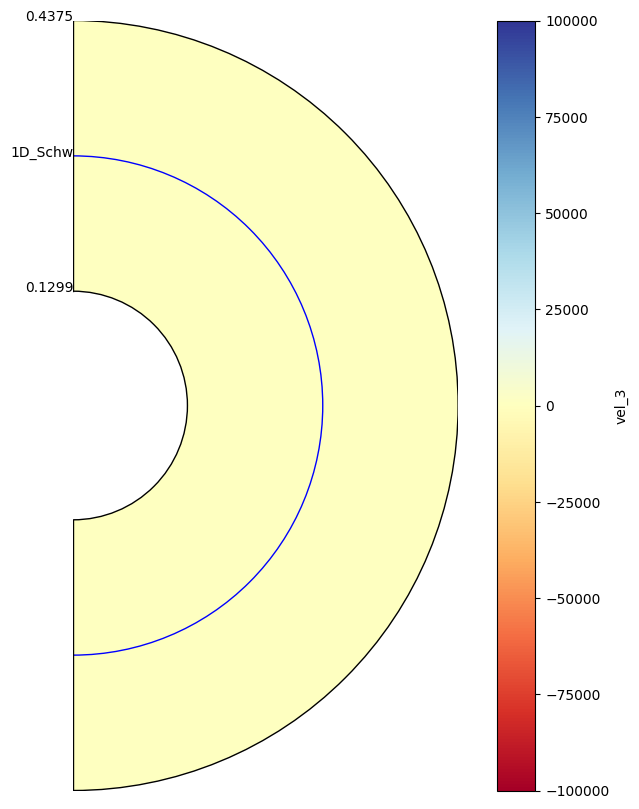

In [70]:
example_plot = vel_plot(sim, n, 3, (-1e5,1e5))

example_plot.savefig(f'20M_ZAMS_hemisphere_Om0_step{n}_vel_3.png', bbox_inches="tight")

In [54]:
cj_plotter.__file__

'/home/cj517/miniconda3/envs/music/lib/python3.11/site-packages/cj_plotter.py'

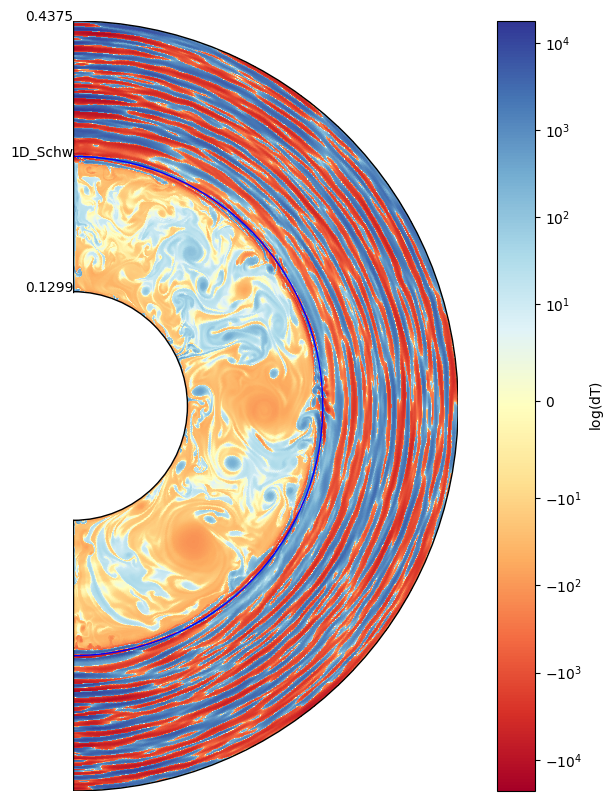

In [71]:
from music_scripts.derived_fields import temp
T = temp(sim[n])
T_arr = T.array()
dT = T_arr - np.mean(T_arr, axis=1)[:, np.newaxis]
r = sim[n].grid.r_grid.cell_points()
t = sim[n].grid.theta_grid.cell_points()
example_plot = cj_plotter.plot2D(t, r/r_tot, dT, log_scale = True, cmap='RdYlBu', figsize=(10,10), linthresh=10) # , visible_ax=False)

example_plot.add_arc(r_env_init/r_tot, edgecolor='blue', label='1D_Schw')
example_plot.colorbar(label=r'$\log(\text{dT})$')
example_plot.savefig(f"20M_ZAMS_hemisphere_Om0_step{n}_dT.png", bbox_inches="tight")

## Video!

In [56]:
cj_plotter.__file__

'/home/cj517/miniconda3/envs/music/lib/python3.11/site-packages/cj_plotter.py'

In [189]:
def make_movie(simulation, field, lims = (-1e5, 1e5), show_time=False, t_conv=None, framerate = 1):
    save_path = f'{simulation.path.parts[-2]}/{field}_figures'
    os.makedirs(save_path, exist_ok = True)
    initial = None
    for i in range(1,sim._len):
        try: sim[i]
        except: continue
        r = sim[i].grid.r_grid.cell_points()
        t = sim[i].grid.theta_grid.cell_points()
        if field == "dT":
            T = temp(sim[i])
            T_arr = T.array()
            value = T_arr - np.mean(T_arr, axis=1)[:, np.newaxis]
            example_plot = cj_plotter.plot2D(t, r/r_tot, value, lims[0], lims[1], log_scale = True, cmap='RdYlBu', figsize=(10,10), linthresh=10)
        else:
            value = sim[i].field[field].array()
            example_plot = cj_plotter.plot2D(t, r/r_tot, value, lims[0], lims[1], cmap='RdYlBu', figsize=(10,10)) # , visible_ax=False)
        
        example_plot.add_arc(r_env_init/r_tot, edgecolor='blue', label='1D_Schw')
        example_plot.colorbar(label=field)
        if show_time == True:
            if initial == None:
                initial = i
            time = (i - initial) * simulation.params["misc"]["dtrec"]
            if t_conv == None: # show true sim time
                example_plot.ax.text(0.35,0.4,r"$\tau$=" + f"{time}", fontsize=12, ha="center")
            else: # show time in units of t_conv
                example_plot.ax.text(0.35,0.4,r"$\tau/\tau_\text{conv}$=" + f"{time / t_conv:.2f}", fontsize=12, ha="center")
        # example_plot.step(np.radians(df['theta_deg'].values), df['r1'].values / r_tot, linestyle='-', label='depth', label_position='bottom')
        
        example_plot.savefig(save_path + f'/20M_ZAMS_{simulation.path.parts[-2]}_step{i}_{field}.png', bbox_inches='tight')
        plt.close()
    pattern = save_path + '/*'

    timestr = strftime("%d-%b-%Y_%H-%M-%S%p", gmtime())
    
    cmd = [
        "ffmpeg", "-y",
        "-loglevel", "error",
        "-f", "image2",
        "-r", str(framerate),
        "-pattern_type", "glob",
        "-i", pattern,
        "-c:v", "libx264",
        "-pix_fmt", "yuv420p",
        "-vf", "pad=ceil(iw/2)*2:ceil(ih/2)*2",
        f"20M_ZAMS_{simulation.path.parts[-2]}_{field}_{timestr}.mp4"
    ]

    # import glob
    # files = sorted(glob.glob(save_path + '/*'))
    # print(len(files), files)
    
    subprocess.run(cmd, check=True)

In [190]:
make_movie(sim, 'dT', show_time=True, t_conv=650892.1, framerate=12)

In [191]:
make_movie(sim, 'vel_1', show_time=True, t_conv=650892.1, framerate=12)

In [192]:
make_movie(sim, 'vel_2', show_time=True, t_conv=650892.1, framerate=12)

In [193]:
make_movie(sim, 'vel_3', show_time=True, t_conv=650892.1, framerate=12)